In [ ]:
# ==========================================================
# DRIVER DISTRACTION DETECTION SYSTEM
# Bölüm 1 - Ortam Kurulumu
# ==========================================================

import os
import random
import numpy as np
import tensorflow as tf

print("=" * 50)
print("TensorFlow Version :", tf.__version__)
print("NumPy Version      :", np.__version__)
print("=" * 50)

# GPU kontrolü
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("✅ GPU bulundu:")
    for gpu in gpus:
        print("   ", gpu)
else:
    print("⚠️ GPU bulunamadı. CPU kullanılacak.")

# Tekrarlanabilir sonuçlar için
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("\nSeed =", SEED)

TensorFlow Version : 2.20.0
NumPy Version      : 2.0.2
✅ GPU bulundu:
    PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

Seed = 42


In [ ]:
# ==========================================================
# 2. KAGGLE API KURULUMU
# ==========================================================

!pip -q install kaggle

import os
import shutil

# Kaggle klasörünü oluştur
os.makedirs("/root/.kaggle", exist_ok=True)

# kaggle.json dosyasını taşı
shutil.copy("kaggle.json", "/root/.kaggle/kaggle.json")

# İzinleri ayarla
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("✅ kaggle.json başarıyla ayarlandı.")
print("")

# Bağlantıyı test et
!kaggle datasets list -s distracted-driver | head

✅ kaggle.json başarıyla ayarlandı.

ref                                                              title                                                    size  lastUpdated                 downloadCount  voteCount  usabilityRating  
---------------------------------------------------------------  -------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
rightway11/state-farm-distracted-driver-detection                State Farm Distracted Driver Detection              546894221  2020-11-02 15:35:18.190000           2936         47  0.29411766       
mikoaro/distracteddriver                                         Distracted-Driver                                  4300429051  2021-08-08 14:03:37.933000           1197         17  0.4375           
sonalshinde123/vehicle-telemetry-for-driver-behavior-analysis    Vehicle Telemetry for Driver Behavior Analysis        2528987  2026-01-14 06:35:55.400000          

In [ ]:
# ==========================================================
# 3. VERİ SETİNİN İNDİRİLMESİ
# ==========================================================

import os

DATASET_NAME = "rightway11/state-farm-distracted-driver-detection"

os.makedirs("/content/dataset", exist_ok=True)

!kaggle datasets download -d $DATASET_NAME -p /content/dataset --unzip

print("\n✅ Veri seti başarıyla indirildi.")

Dataset URL: https://www.kaggle.com/datasets/rightway11/state-farm-distracted-driver-detection
License(s): unknown
100% 522M/522M [00:26<00:00, 20.7MB/s]


✅ Veri seti başarıyla indirildi.


In [ ]:
# ==========================================================
# 3. VERİ SETİNİ İNCELEME
# ==========================================================

import os

train_dir = "/content/dataset/imgs/train"

classes = sorted(os.listdir(train_dir))

print("=" * 50)
print("Toplam Sınıf Sayısı :", len(classes))
print("=" * 50)

total_images = 0

for cls in classes:
    class_path = os.path.join(train_dir, cls)
    image_count = len(os.listdir(class_path))
    total_images += image_count

    print(f"{cls:<5} : {image_count}")

print("=" * 50)
print("Toplam Eğitim Görüntüsü :", total_images)
print("=" * 50)

Toplam Sınıf Sayısı : 10
c0    : 1953
c1    : 1754
c2    : 1783
c3    : 1809
c4    : 1817
c5    : 1804
c6    : 1811
c7    : 1532
c8    : 1518
c9    : 1681
Toplam Eğitim Görüntüsü : 17462


In [ ]:
# ==========================================================
# 4. VERİ YÜKLEME AYARLARI
# ==========================================================

# Dataset yolu
DATASET_DIR = "/content/dataset/imgs/train"

# Görüntü boyutu
IMG_SIZE = (224, 224)

# Batch size
BATCH_SIZE = 16

# Validation oranı
VALIDATION_SPLIT = 0.20

# Sınıf isimleri
CLASS_NAMES = sorted(os.listdir(DATASET_DIR))

print("=" * 50)
print("Dataset :", DATASET_DIR)
print("Image Size :", IMG_SIZE)
print("Batch Size :", BATCH_SIZE)
print("Validation Split :", VALIDATION_SPLIT)
print("Classes :", CLASS_NAMES)
print("=" * 50)

Dataset : /content/dataset/imgs/train
Image Size : (224, 224)
Batch Size : 16
Validation Split : 0.2
Classes : ['c0', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9']


In [ ]:
# ==========================================================
# 7. DATA AUGMENTATION
# ==========================================================

from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

print("✅ Data Augmentation hazır.")

✅ Data Augmentation hazır.


In [ ]:
# ==========================================================
# 8. NORMALIZATION
# ==========================================================

from tensorflow.keras.applications.efficientnet import preprocess_input

preprocessing = layers.Lambda(preprocess_input)

print("✅ EfficientNet preprocessing hazır.")

✅ EfficientNet preprocessing hazır.


In [ ]:
# ==========================================================
# 9. EFFICIENTNETB0 MODEL
# ==========================================================

from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, Model

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))

x = data_augmentation(inputs)
x = preprocessing(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    len(CLASS_NAMES),
    activation="softmax"
)(x)

model = Model(inputs=inputs, outputs=outputs)

print(model.input_shape)

(None, 224, 224, 3)


In [ ]:
# ==========================================================
# 10. CALLBACKS
# ==========================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        "best_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )

]

print("✅ Callbacks hazır.")

✅ Callbacks hazır.


In [ ]:
# ==========================================================
# 11. MODEL COMPILE
# ==========================================================

model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),

    loss="categorical_crossentropy",

    metrics=[
        "accuracy"
    ]

)

print("✅ Model compile edildi.")

✅ Model compile edildi.


In [ ]:
# ==========================================================
# TÜM DOSYA YOLLARINI OKU
# ==========================================================

import os

image_paths = []
labels = []

CLASS_NAMES = sorted(os.listdir(DATASET_DIR))

for label_index, class_name in enumerate(CLASS_NAMES):

    class_dir = os.path.join(DATASET_DIR, class_name)

    for image_name in os.listdir(class_dir):

        image_paths.append(
            os.path.join(class_dir, image_name)
        )

        labels.append(label_index)

print("Toplam resim :", len(image_paths))
print("Toplam label :", len(labels))
print(CLASS_NAMES)

Toplam resim : 17462
Toplam label : 17462
['c0', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9']


In [ ]:
# ==========================================================
# TRAIN / VALIDATION SPLIT
# ==========================================================

from sklearn.model_selection import train_test_split

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Train :", len(train_paths))
print("Validation :", len(val_paths))

Train : 13969
Validation : 3493


In [ ]:
from collections import Counter

print("Train dağılımı")
print(Counter(train_labels))

print("\nValidation dağılımı")
print(Counter(val_labels))

Train dağılımı
Counter({0: 1562, 4: 1454, 6: 1449, 3: 1447, 5: 1443, 2: 1426, 1: 1403, 9: 1345, 7: 1226, 8: 1214})

Validation dağılımı
Counter({0: 391, 4: 363, 3: 362, 6: 362, 5: 361, 2: 357, 1: 351, 9: 336, 7: 306, 8: 304})


In [ ]:
# ==========================================================
# TF.DATA DATASET OLUŞTUR
# ==========================================================

import tensorflow as tf

AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):

    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)

    image = tf.image.resize(image, IMG_SIZE)

    image = tf.cast(image, tf.float32)

    label = tf.one_hot(label, depth=len(CLASS_NAMES))

    return image, label


train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

In [ ]:
train_ds = (
    train_ds
    .shuffle(len(train_paths))
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Train batches :", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches :", tf.data.experimental.cardinality(val_ds).numpy())

Train batches : 874
Validation batches : 219


In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
874/874 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.3933 - loss: 1.7946
Epoch 1: val_accuracy improved from None to 0.73347, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
874/874 ━━━━━━━━━━━━━━━━━━━━ 71s 62ms/step - accuracy: 0.5455 - loss: 1.4440 - val_accuracy: 0.7335 - val_loss: 0.9980 - learning_rate: 0.0010
Epoch 2/10
873/874 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.7167 - loss: 0.9526
Epoch 2: val_accuracy improved from 0.73347 to 0.83023, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
874/874 ━━━━━━━━━━━━━━━━━━━━ 51s 58ms/step - accuracy: 0.7342 - loss: 0.8973 - val_accuracy: 0.8302 - val_loss: 0.7134 - learning_rate: 0.0010
Epoch 3/10
874/874 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.7689 - loss: 0.7716
Epoch 3: val_accuracy did not improve from 0.83023
874/874 ━━━━━━━━━━━━━━━━━━━━ 50s 58ms/step - accuracy: 0.7735 - loss: 0.7476 - val_accuracy: 0.8265 - val_loss: 0.6448 - le

In [ ]:
import numpy as np

y_true = []
y_pred = []

for images, labels in val_ds:

    predictions = model.predict(images, verbose=0)

    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(np.unique(y_true))

[0 1 2 3 4 5 6 7 8 9]


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4
    )
)

              precision    recall  f1-score   support

          c0     0.9309    0.7238    0.8144       391
          c1     0.8981    0.9544    0.9254       351
          c2     0.8357    0.9692    0.8975       357
          c3     0.8657    0.9613    0.9110       362
          c4     0.9379    0.9146    0.9261       363
          c5     0.9888    0.9806    0.9847       361
          c6     0.8460    0.9254    0.8839       362
          c7     0.8912    0.9902    0.9381       306
          c8     0.9078    0.6480    0.7562       304
          c9     0.8657    0.8631    0.8644       336

    accuracy                         0.8941      3493
   macro avg     0.8968    0.8931    0.8902      3493
weighted avg     0.8973    0.8941    0.8911      3493



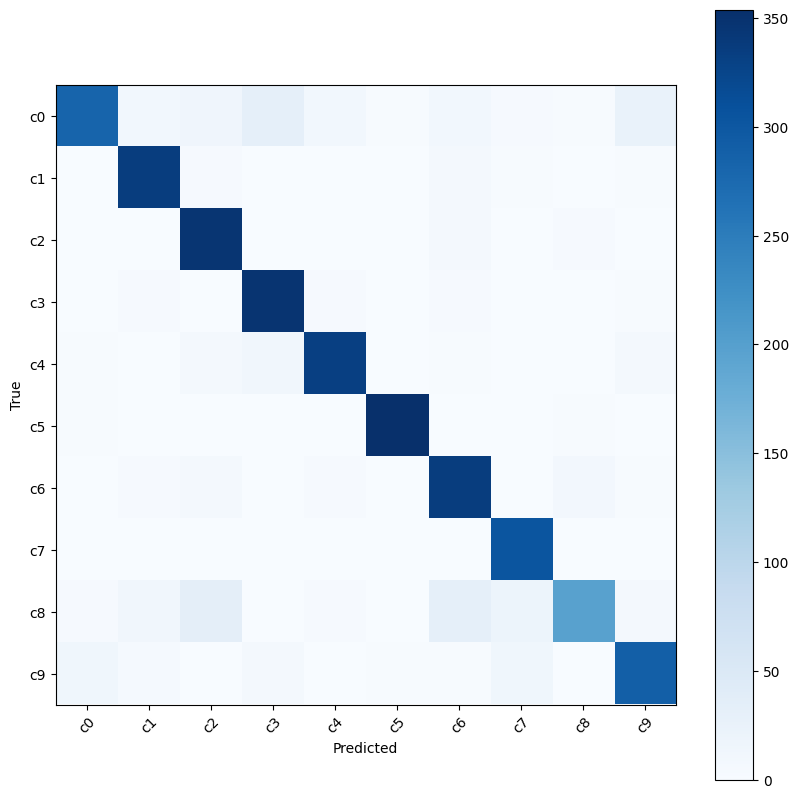

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10,10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks(range(10), CLASS_NAMES, rotation=45)
plt.yticks(range(10), CLASS_NAMES)

plt.xlabel("Predicted")
plt.ylabel("True")

plt.show()

In [ ]:
# ==========================================================
# VALIDATION TAHMİNLERİNİ KAYDET
# ==========================================================

predictions = model.predict(val_ds, verbose=1)

pred_classes = np.argmax(predictions, axis=1)
true_classes = np.array(val_labels)

219/219 ━━━━━━━━━━━━━━━━━━━━ 18s 57ms/step


In [ ]:
# ==========================================================
# YANLIŞ TAHMİNLER
# ==========================================================

wrong_indexes = np.where(pred_classes != true_classes)[0]

print("Toplam yanlış tahmin :", len(wrong_indexes))

Toplam yanlış tahmin : 370


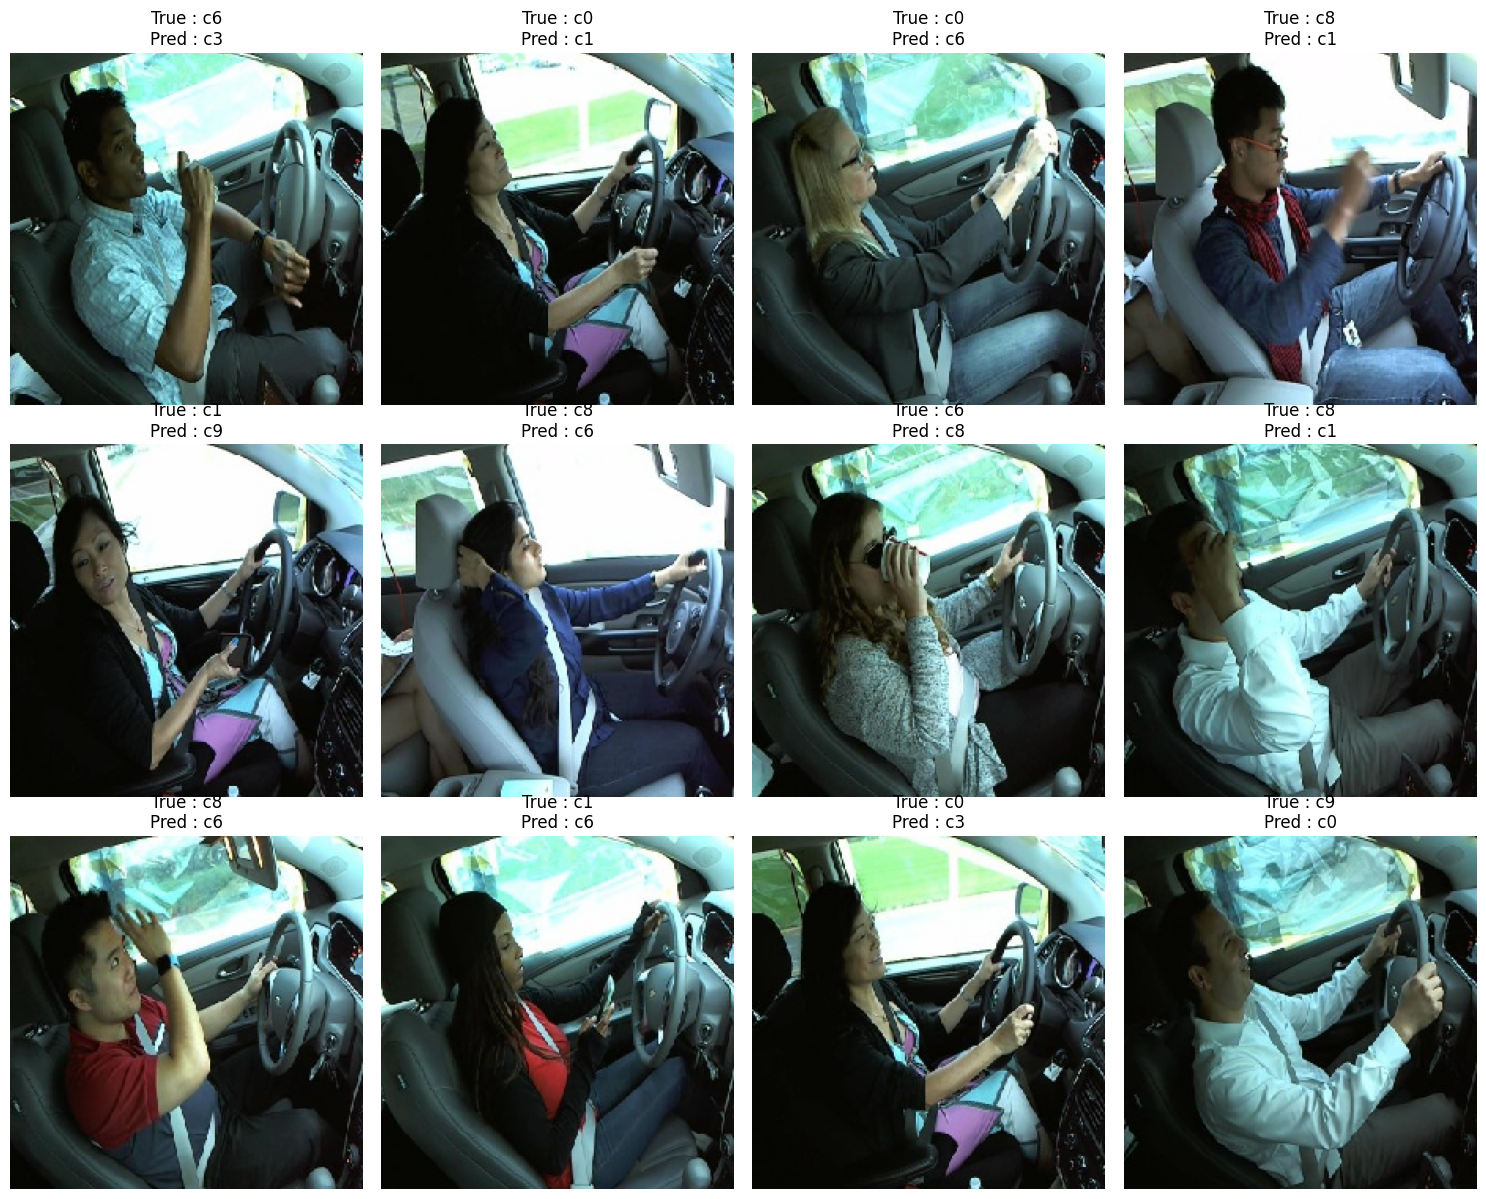

In [ ]:
# ==========================================================
# İLK 12 YANLIŞ TAHMİN
# ==========================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(15,12))

for i, idx in enumerate(wrong_indexes[:12]):

    image = tf.keras.utils.load_img(
        val_paths[idx],
        target_size=IMG_SIZE
    )

    plt.subplot(3,4,i+1)

    plt.imshow(image)

    plt.title(
        f"True : {CLASS_NAMES[true_classes[idx]]}\n"
        f"Pred : {CLASS_NAMES[pred_classes[idx]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================================
# 16. FINE TUNING
# ==========================================================

base_model.trainable = True

print("Toplam katman:", len(base_model.layers))

Toplam katman: 238


In [ ]:
# Son 30 katman eğitilecek
fine_tune_at = len(base_model.layers) - 30

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

for layer in base_model.layers[fine_tune_at:]:
    layer.trainable = True

print("Fine-tuning başlangıç katmanı:", fine_tune_at)

Fine-tuning başlangıç katmanı: 208


In [ ]:
from tensorflow.keras.layers import BatchNormalization

for layer in base_model.layers:
    if isinstance(layer, BatchNormalization):
        layer.trainable = False

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("✅ Fine-tuning compile tamam.")

✅ Fine-tuning compile tamam.


In [ ]:
FINE_TUNE_EPOCHS = 10

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=callbacks
)

Epoch 1/10
874/874 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.8497 - loss: 0.4710
Epoch 1: val_accuracy improved from 0.89407 to 0.92642, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
874/874 ━━━━━━━━━━━━━━━━━━━━ 74s 69ms/step - accuracy: 0.8613 - loss: 0.4307 - val_accuracy: 0.9264 - val_loss: 0.2643 - learning_rate: 1.0000e-05
Epoch 2/10
874/874 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.8938 - loss: 0.3437
Epoch 2: val_accuracy improved from 0.92642 to 0.94732, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
874/874 ━━━━━━━━━━━━━━━━━━━━ 56s 64ms/step - accuracy: 0.8919 - loss: 0.3477 - val_accuracy: 0.9473 - val_loss: 0.2048 - learning_rate: 1.0000e-05
Epoch 3/10
873/874 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.9043 - loss: 0.3097
Epoch 3: val_accuracy improved from 0.94732 to 0.95391, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
874/874 ━━━━━━━━━━━━━━

In [ ]:
predictions = model.predict(val_ds, verbose=1)

pred_classes = np.argmax(predictions, axis=1)
true_classes = np.array(val_labels)

219/219 ━━━━━━━━━━━━━━━━━━━━ 19s 59ms/step


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        true_classes,
        pred_classes,
        target_names=CLASS_NAMES,
        digits=4
    )
)

              precision    recall  f1-score   support

          c0     0.9424    0.9616    0.9519       391
          c1     0.9915    0.9943    0.9929       351
          c2     0.9699    0.9916    0.9806       357
          c3     0.9917    0.9917    0.9917       362
          c4     0.9862    0.9835    0.9848       363
          c5     0.9972    0.9861    0.9916       361
          c6     0.9753    0.9807    0.9780       362
          c7     0.9838    0.9902    0.9870       306
          c8     0.9529    0.9309    0.9418       304
          c9     0.9602    0.9345    0.9472       336

    accuracy                         0.9751      3493
   macro avg     0.9751    0.9745    0.9747      3493
weighted avg     0.9751    0.9751    0.9750      3493



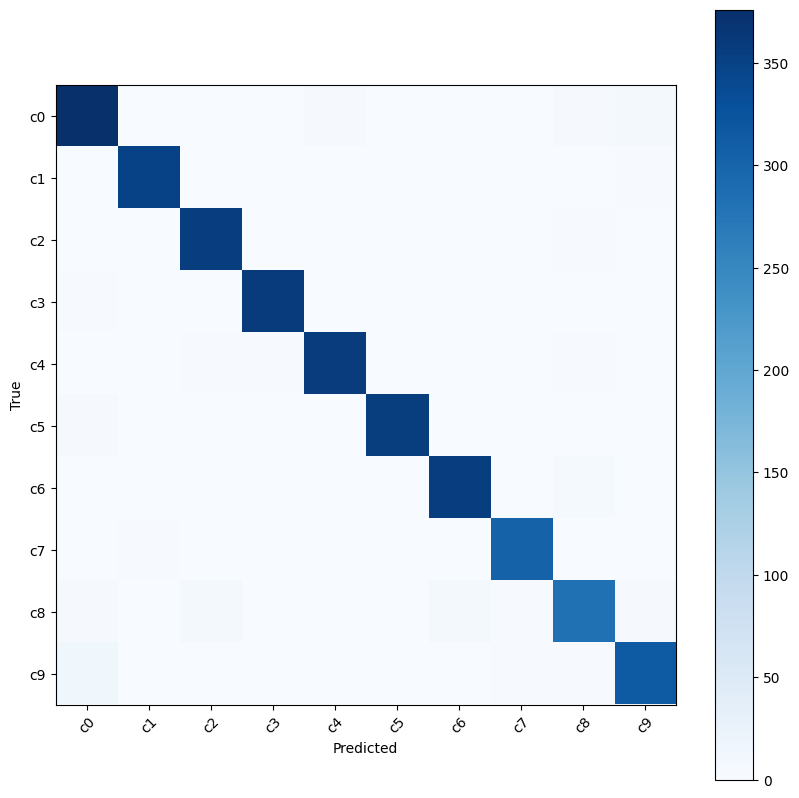

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(true_classes, pred_classes)

plt.figure(figsize=(10,10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks(range(10), CLASS_NAMES, rotation=45)
plt.yticks(range(10), CLASS_NAMES)

plt.xlabel("Predicted")
plt.ylabel("True")

plt.show()

In [ ]:
model.save("Driver_Distraction_EfficientNetB0.keras")